# Check the phase assumption against the aircraft's own temperature

A "warm cloud" campaign label is not evidence that every flight sampled liquid cloud: of eight
synthetic flights, 4 put enough of their in-cloud seconds below 0 °C, or in the −3 to −8 °C
rime-splintering band, to fail a liquid-only check, one of them with 84.3 % of its cloud below
freezing. Restricting the analysis to seconds above 0 °C keeps it honest and costs 19.3 % of the
in-cloud sample (60611 to 48906 seconds). The same temperature test, applied second by second on a
flight that crosses the freezing level, splits it into 1233 liquid and 1272 ice seconds, so two
products' moments are compared per phase rather than mixed.

> **Every number in this notebook is synthetic.** The flights, their temperature record and the
> droplet-probe concentration are drawn from a fixed-seed random-number generator in section 1; no
> data file is read.

**The problem.** A campaign is often described by its cloud type: "warm stratocumulus",
"liquid-only boundary-layer cloud". An analysis then inherits that description as an assumption —
every particle is a drop, every image is a sphere, every mass is a volume of water — without
anyone checking it flight by flight. The check costs one variable the aircraft already records:
its static air temperature. Cloud sampled below 0 °C may hold supercooled drops, ice, or both, and
cloud between −3 and −8 °C is the band where rime splintering (Hallett–Mossop) can multiply ice
quickly. A liquid-only assumption is safe for a flight only when its in-cloud seconds stay above 0 °C.

**The sections.** (1) synthetic flights; (2) in-cloud seconds from a droplet-probe concentration
threshold, and per flight the fraction below 0 °C and the time in the −3 to −8 °C band; (3) a plot
of both; (4) flag the flights where the assumption is unsafe; (5) restrict an analysis to above-0 °C
seconds and say how much the sample shrinks; (6) what to check next on a flagged flight; (7) class
each second by phase and compare two products' moments per class.

**Before this:** [05_triage_and_gallery](../1_getting_started/05_triage_and_gallery.ipynb) (Looking at particles: a contact sheet, a gallery, and the triage page). **Related:** [01_microphysics_moments](../6_science/01_microphysics_moments.ipynb). **Needs:** `pip install "arrayprobe[extra]"` (matplotlib).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/5_data_quality/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

Build eight synthetic flights of three hours each, with a temperature and a cloud-droplet concentration for every second. A few flights are given legs in sub-zero cloud on purpose, so the check in the next sections has a known answer to find.

In [2]:
"""1. Eight synthetic flights at 1 Hz: temperature, and a droplet-probe concentration."""
import numpy as np

rng = np.random.default_rng(20261002)
N_FLIGHTS = 8
N_SECONDS = 3 * 3600                     # three hours per flight

# Each flight samples cloud on level legs. Most flights' legs sit in warm cloud; on a few the
# cloud layer reaches above the freezing level, so some legs are flown in sub-zero cloud.
# `cold_share` is the invented fraction of legs flown above the freezing level on each flight.
cold_share = np.array([0.0, 0.0, 0.05, 0.0, 0.35, 0.0, 0.6, 0.15])

flights = []
for f in range(N_FLIGHTS):
    temp = np.empty(N_SECONDS)
    cloudy = np.zeros(N_SECONDS, dtype=bool)
    t = 0
    while t < N_SECONDS:
        leg = int(rng.integers(300, 900))               # a level leg of 5-15 minutes
        if rng.random() < cold_share[f]:
            leg_temp = rng.uniform(-12.0, -1.0)         # above the freezing level
        else:
            leg_temp = rng.uniform(1.0, 14.0)           # below it
        temp[t:t + leg] = leg_temp + rng.normal(0.0, 0.3, temp[t:t + leg].size)
        cloudy[t:t + leg] = rng.random(temp[t:t + leg].size) < 0.7   # broken cloud on the leg
        t += leg
    # Droplet concentration (cm^-3): lognormal in cloud, a near-zero noise floor in clear air.
    conc = np.where(cloudy,
                    rng.lognormal(np.log(150.0), 0.5, N_SECONDS),
                    rng.exponential(0.5, N_SECONDS))
    flights.append({"name": f"flight {f + 1}", "temp_c": temp, "conc_cm3": conc})

print(f"{N_FLIGHTS} flights x {N_SECONDS} s; temperature range "
      f"{min(fl['temp_c'].min() for fl in flights):.1f} to "
      f"{max(fl['temp_c'].max() for fl in flights):.1f} degC")

8 flights x 10800 s; temperature range -12.5 to 14.9 degC


## 2. Four of eight flights put some of their cloud below 0 °C

A second is in cloud when the droplet probe's concentration exceeds a threshold. The threshold is
a choice the analysis should state; 10 cm⁻³ is used here because the synthetic clear-air floor sits
far below it. Per flight the table gives the in-cloud seconds, the fraction of them below 0 °C and
the seconds spent in the −3 to −8 °C rime-splintering band.

In [3]:
"""2. Per-flight phase summary."""
CLOUD_THRESHOLD_CM3 = 10.0
SPLINTER_BAND_C = (-8.0, -3.0)

rows = []
for fl in flights:
    in_cloud = fl["conc_cm3"] > CLOUD_THRESHOLD_CM3
    t_cloud = fl["temp_c"][in_cloud]
    below_zero = t_cloud < 0.0
    in_band = (t_cloud >= SPLINTER_BAND_C[0]) & (t_cloud <= SPLINTER_BAND_C[1])
    fl["in_cloud"] = in_cloud
    rows.append({"name": fl["name"], "n_cloud": int(in_cloud.sum()),
                 "frac_below_0": below_zero.mean() if t_cloud.size else 0.0,
                 "band_s": int(in_band.sum()), "t_min_cloud": t_cloud.min()})

print(f"{'flight':10s} {'in-cloud s':>10s} {'below 0 C':>10s} {'-3..-8 C (s)':>13s} {'coldest (C)':>12s}")
for r in rows:
    print(f"{r['name']:10s} {r['n_cloud']:10d} {100 * r['frac_below_0']:9.1f}% "
          f"{r['band_s']:13d} {r['t_min_cloud']:12.1f}")

flight     in-cloud s  below 0 C  -3..-8 C (s)  coldest (C)
flight 1         7527       0.0%             0          1.3
flight 2         7558       0.0%             0          1.0
flight 3         7558      17.0%            75        -11.2
flight 4         7582       0.0%             0          1.0
flight 5         7638      40.0%          1388        -12.5
flight 6         7621       0.0%             0          1.9
flight 7         7533      84.3%          1721        -12.0
flight 8         7594      13.3%           112        -10.8


Plot the two numbers per flight side by side: the share of in-cloud time below freezing, and the minutes spent in the temperature band where ice can multiply by rime splintering. A tall bar in either panel marks a flight that a liquid-only analysis should not include.

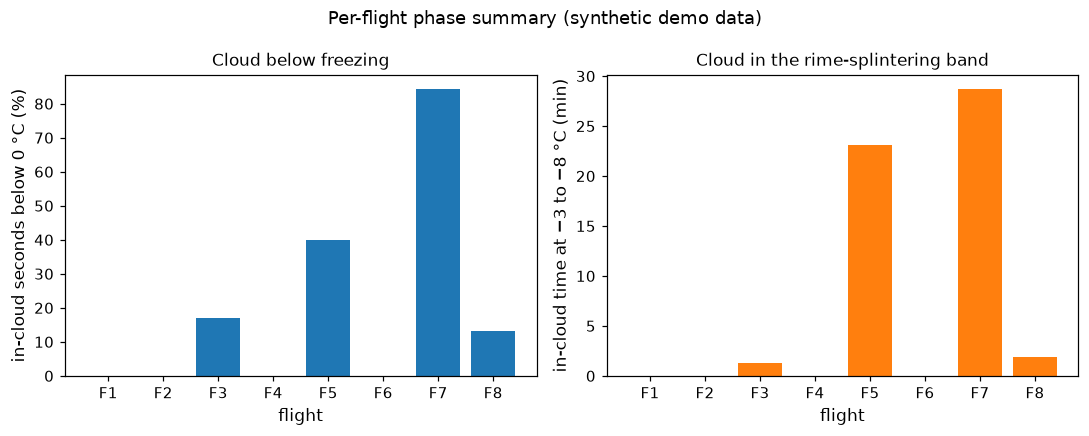

In [4]:
"""3. The two numbers per flight, side by side."""
import matplotlib.pyplot as plt

names = [r["name"].replace("flight ", "F") for r in rows]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.bar(names, [100 * r["frac_below_0"] for r in rows], color="tab:blue")
ax1.set_ylabel("in-cloud seconds below 0 °C (%)", fontsize=11)
ax1.set_title("Cloud below freezing", fontsize=11)
ax2.bar(names, [r["band_s"] / 60 for r in rows], color="tab:orange")
ax2.set_ylabel("in-cloud time at −3 to −8 °C (min)", fontsize=11)
ax2.set_title("Cloud in the rime-splintering band", fontsize=11)
for ax in (ax1, ax2):
    ax.set_xlabel("flight", fontsize=11)
    ax.tick_params(labelsize=10)
fig.suptitle("Per-flight phase summary (synthetic demo data)", fontsize=12)
fig.tight_layout()
plt.show()

*Figure 1. For each of the eight synthetic flights, the share of in-cloud seconds below 0 °C (left) and the in-cloud minutes spent between −3 and −8 °C, the rime-splintering band (right). Flights with no bar sampled only warm cloud.*

## 4. Four of eight flights fail the liquid-only check

The rule below is deliberately simple and its two limits are choices to state, not constants of
nature: a flight is flagged when more than 1 % of its in-cloud seconds are below 0 °C, or when it
spent more than one minute of cloud in the rime-splintering band. A flagged flight is not shown to
contain ice — only shown to have sampled cloud where ice was possible, so the liquid-only
assumption needs evidence there rather than a campaign description.

In [5]:
"""4. The flag."""
MAX_FRAC_BELOW_0 = 0.01
MAX_BAND_SECONDS = 60


def phase_flag(row):
    reasons = []
    if row["frac_below_0"] > MAX_FRAC_BELOW_0:
        reasons.append(f"{100 * row['frac_below_0']:.1f}% of cloud below 0 C")
    if row["band_s"] > MAX_BAND_SECONDS:
        reasons.append(f"{row['band_s']} s in the -3 to -8 C band")
    return reasons


flagged = []
for r in rows:
    reasons = phase_flag(r)
    verdict = "UNSAFE: " + "; ".join(reasons) if reasons else "liquid-only assumption holds"
    print(f"{r['name']:10s} {verdict}")
    if reasons:
        flagged.append(r["name"])
print(f"\n{len(flagged)} of {len(rows)} flights flagged")

flight 1   liquid-only assumption holds
flight 2   liquid-only assumption holds
flight 3   UNSAFE: 17.0% of cloud below 0 C; 75 s in the -3 to -8 C band
flight 4   liquid-only assumption holds
flight 5   UNSAFE: 40.0% of cloud below 0 C; 1388 s in the -3 to -8 C band
flight 6   liquid-only assumption holds
flight 7   UNSAFE: 84.3% of cloud below 0 C; 1721 s in the -3 to -8 C band
flight 8   UNSAFE: 13.3% of cloud below 0 C; 112 s in the -3 to -8 C band

4 of 8 flights flagged


## 5. Keeping only above-0 °C cloud costs 19.3 % of the sample

Where the analysis truly needs liquid cloud, keep only in-cloud seconds above 0 °C — with a small
margin for the temperature sensor's own uncertainty (here +0.5 °C; use your sensor's stated figure).
Report how much the sample shrinks, overall and per flight, so a reader knows what was left out.

In [6]:
"""5. The warm-cloud sample and how much smaller it is."""
MARGIN_C = 0.5

total_before = total_after = 0
for fl in flights:
    warm = fl["in_cloud"] & (fl["temp_c"] > MARGIN_C)
    fl["warm_cloud"] = warm                        # the mask a downstream analysis should use
    n0, n1 = int(fl["in_cloud"].sum()), int(warm.sum())
    total_before += n0
    total_after += n1
    print(f"{fl['name']:10s} {n0:6d} -> {n1:6d} in-cloud seconds ({100 * (1 - n1 / n0):5.1f}% removed)")
print(f"{'all':10s} {total_before:6d} -> {total_after:6d} in-cloud seconds "
      f"({100 * (1 - total_after / total_before):.1f}% removed)")

flight 1     7527 ->   7527 in-cloud seconds (  0.0% removed)
flight 2     7558 ->   7558 in-cloud seconds (  0.0% removed)
flight 3     7558 ->   6272 in-cloud seconds ( 17.0% removed)
flight 4     7582 ->   7582 in-cloud seconds (  0.0% removed)
flight 5     7638 ->   4581 in-cloud seconds ( 40.0% removed)
flight 6     7621 ->   7621 in-cloud seconds (  0.0% removed)
flight 7     7533 ->   1186 in-cloud seconds ( 84.3% removed)
flight 8     7594 ->   6579 in-cloud seconds ( 13.4% removed)
all         60611 ->  48906 in-cloud seconds (19.3% removed)


## 6. Temperature says ice was possible; four checks say whether it was there

Temperature says where ice was *possible*; these say whether it was *there*:

- **Imaging-probe habit.** On the flagged seconds, look at the particle images and their habit
  classification: a liquid-only cloud images as round particles; columns, plates, aggregates or
  irregular shapes are ice. Notebook [`05_triage_and_gallery.ipynb`](../1_getting_started/05_triage_and_gallery.ipynb) shows the gallery and triage tools.
  A habit is a shape class, not a phase: Schima et al. (2024) define their sphere class as "liquid droplets or ice crystals that are almost spherical", and on the HVPS 85 % of their hand-labelled spheres were classified as graupel. The next note gives the further limits of reading phase from images.
- **An ice/liquid classifier.** Run a particle-by-particle phase classifier (or label a sample by
  hand) over the flagged seconds and over a warm control set, and compare the ice fractions.
- **Water-content probes that disagree.** A probe sensitive only to liquid water and one that
  measures total (liquid plus ice) water read alike in liquid cloud and diverge when ice is
  present; their difference on the flagged seconds is an independent ice signal.
- **The temperature record itself.** Check its stated uncertainty and any in-cloud wetting
  artefact before trusting a margin of a fraction of a degree.

### Images give shape, not phase

An image shows a shadow, and a shadow's shape is not its phase. Schima et al. (2022), who classified phase in Southern Ocean boundary-layer cloud from several probes together, state the limits of the 2D-S images they used:

- **Small particles cannot be told apart.** Many droplets are too small to be imaged at all, and at the probe's resolution the shapes of small ice crystals are hard to distinguish from small droplets (Schima et al., 2022, section 2.1).
- **Round and non-round counts are not liquid and ice counts.** Some ice crystals are inevitably counted as round, so a round-particle concentration is not a liquid concentration (section 2.1).
- **Large round particles can be ice.** In one region where large round particles had been counted, the 2D-C and PHIPS images showed no supercooled large drops and instead ice crystals (rimed needles, needle aggregates and faceted shapes), so a round-particle count was not evidence of liquid (section 3). Out-of-focus drizzle drops can also appear donut-shaped, that is hollow, though they are liquid (section 2.1).
- **Thresholds for supercooled large drops are tuning choices, and the answer depends on them.** The authors set a round-fraction threshold of 0.3 and a concentration threshold of 1 L⁻¹, the latter chosen to match the remote-sensing classification. With the lower value of 0.085 L⁻¹, the frequency of supercooled large drops near cloud top rose from about 5 to 10 % to 40 to 65 % (Appendix B). State every threshold you use and rerun the analysis over a range of values.
- **Use other evidence together with the images.** Their phase came from several probes together and from reviewing images by hand, with counts averaged over 3 s because 1 s holds too few particles.

Habit codes, sphericity and area ratio are therefore shape measurements. Use them as one line of evidence, next to the temperature test above, and class a second as unclassified when the evidence does not settle it.

**References.**

Brown, P. R. A. and Francis, P. N.: Improved measurements of the ice water content in cirrus using a total-water probe, J. Atmos. Oceanic Technol., 12, 410-414, 1995 (the ice mass relation of section 7b, Eq. 3).

Schima, J., McFarquhar, G., Romatschke, U., Vivekanandan, J., D'Alessandro, J., Haggerty, J., Wolff, C., Schaefer, E., Järvinen, E., and Schnaiter, M.: Characterization of Southern Ocean Boundary Layer Clouds Using Airborne Radar, Lidar, and In Situ Cloud Data: Results From SOCRATES, J. Geophys. Res. Atmos., 127(21), e2022JD037277, https://doi.org/10.1029/2022JD037277, 2022.

Schima, J., McFarquhar, G. M., Delene, D., Heymsfield, A., Bansemer, A., Schnaiter, M., Finlon, J. A., Järvinen, E., and Nehlert, F.: A Multi-Probe Automated Classification of Ice Crystal Habits During the IMPACTS Campaign, J. Geophys. Res. Atmos., 129, e2024JD040895, https://doi.org/10.1029/2024JD040895, 2024.

## 7. On a flight that crosses the freezing level, compare two products per phase

The temperature test that flagged whole flights above also classes each second, which a
comparison of two products needs before it quotes a liquid or an ice water content. The next two
cells set up two synthetic flights seen by two products of one probe, and the moment function
(the same set-up as [`01_microphysics_moments.ipynb`](../6_science/01_microphysics_moments.ipynb), sections 1 and 2).

In [7]:
"""7a. Two synthetic flights at 1 Hz, each seen by two products of one probe."""
import numpy as np

rng = np.random.default_rng(20261003)

# Bin ladder: 40 log-spaced bins from 55 to 3000 um (edges), midpoints in um.
EDGES = np.geomspace(55.0, 3000.0, 41)
MID = np.sqrt(EDGES[:-1] * EDGES[1:])
N_SEC = 3600

# The two products differ in exactly two ways, both invented and both known here:
#   sample volume per second (litres): B's is 60 % of A's, so B's one-count quantum is larger;
#   detection efficiency: B detects 75 % of the particles below 100 um that A detects.
SV_A, SV_B = 25.0, 15.0
EFF_B = np.where(MID < 100.0, 0.75, 1.0)

def true_psd(n_per_l, dm_um, mu=2.0):
    """Gamma-shaped number per bin (per litre) for a total n_per_l and mean diameter dm_um."""
    shape = MID ** mu * np.exp(-(mu + 1.0) * MID / dm_um) * np.diff(EDGES)
    return n_per_l * shape / shape.sum()

def make_flight(name, temp):
    """A flight: in-cloud mask, the true bin concentration ΔN_i per second, and each product's concentration."""
    cloudy = rng.random(N_SEC) < 0.7
    n_tot = np.where(cloudy, rng.lognormal(np.log(0.8), 0.6, N_SEC), 0.0)       # per litre
    dm = np.where(temp < 0.0, 450.0, 160.0) * rng.lognormal(0.0, 0.2, N_SEC)
    truth = np.array([true_psd(n, d) for n, d in zip(n_tot, dm)])               # (sec, bin)
    counts_a = rng.poisson(truth * SV_A)
    counts_b = rng.poisson(truth * SV_B * EFF_B)
    return {"name": name, "temp": temp, "cloudy": cloudy, "truth": truth,
            "conc_a": counts_a / SV_A, "conc_b": counts_b / SV_B,                # per litre per bin
            "counts_a": counts_a, "counts_b": counts_b}

t = np.arange(N_SEC)
temp_warm = 9.0 + 1.5 * np.sin(2 * np.pi * t / 1800) + rng.normal(0, 0.2, N_SEC)
temp_cold = np.where(t < 1800, 3.0, -9.0) + rng.normal(0, 0.4, N_SEC)          # second half sub-zero
warm = make_flight("flight W (all above 0 C)", temp_warm)
cold = make_flight("flight C (half below 0 C)", temp_cold)
print(f"{len(MID)} bins, {N_SEC} s per flight; in-cloud seconds: "
      f"W {warm['cloudy'].sum()}, C {cold['cloudy'].sum()}")

40 bins, 3600 s per flight; in-cloud seconds: W 2493, C 2505


Define a function that reduces one size distribution to bulk numbers: total number, mean, median-volume and effective diameter, liquid and ice water content, and radar reflectivity. It is applied to the warm flight's true distribution to show the values it returns.

In [8]:
"""7b. Moments of one size distribution."""
def moments(conc):
    """N (L^-1), D_mean, D_mvd, D_eff (um), LWC and IWC (g m^-3), Z (dBZ) of one distribution."""
    conc = np.asarray(conc, dtype=float)
    n = conc.sum()
    if n <= 0:
        return dict(N=0.0, D_mean=np.nan, D_mvd=np.nan, D_eff=np.nan, LWC=0.0, IWC=0.0, Z_dBZ=np.nan)
    per_m3 = conc * 1e3
    m3 = per_m3 * MID ** 3
    cum = np.cumsum(m3) / m3.sum()
    k = int(np.searchsorted(cum, 0.5))                       # bin in which half the volume is crossed
    lo = cum[k - 1] if k else 0.0
    d_mvd = EDGES[k] + (0.5 - lo) / (cum[k] - lo) * (EDGES[k + 1] - EDGES[k])
    lwc = (np.pi / 6.0) * 1.0 * np.sum(per_m3 * (MID * 1e-4) ** 3)                  # g m^-3
    m_ice = np.where(MID < 100.0, 4.82e-13 * MID ** 3, 7.38e-11 * MID ** 1.9)     # g; Brown and Francis (1995) eq. 3
    iwc = np.sum(per_m3 * m_ice)                                                    # g m^-3
    z = np.sum(per_m3 * (MID * 1e-3) ** 6)                                          # mm^6 m^-3
    return dict(N=n, D_mean=np.sum(conc * MID) / n, D_mvd=d_mvd,
                D_eff=np.sum(conc * MID ** 3) / np.sum(conc * MID ** 2),
                LWC=lwc, IWC=iwc, Z_dBZ=10 * np.log10(z) if z > 0 else np.nan)

for k, v in moments(warm["truth"][warm["cloudy"]].mean(axis=0)).items():
    print(f"{k:7s} {v:10.4g}")

N           0.9688
D_mean       174.8
D_mvd        337.1
D_eff        293.6
LWC        0.00596
IWC       0.001632
Z_dBZ      -0.1027


### 7c. Per phase, the two products' Z differs by +0.49 dB on liquid seconds and −0.67 dB on ice

Flight C crosses the freezing level half-way. Each in-cloud second is classed from the
aircraft's temperature (here the only evidence; on real data, add a droplet-probe liquid test and
the imaging probe's irregular-particle fraction, and class a second with no shape evidence as
*unclassified*, never as regular). LWC is then reported only for liquid seconds and IWC only for
ice seconds; elsewhere the cell is NaN and says so.

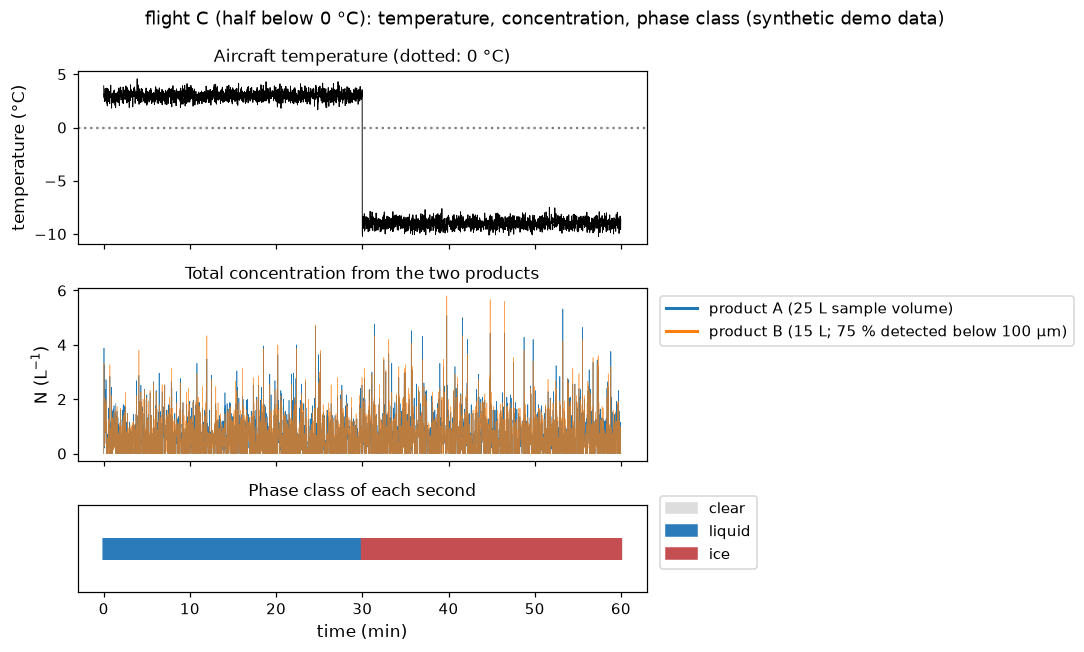

In [9]:
"""7c. Per-second phase strip for flight C, and moments per phase class."""
import matplotlib.pyplot as plt

phase = np.full(N_SEC, "clear", dtype=object)
phase[cold["cloudy"] & (cold["temp"] >= 0)] = "liquid"
phase[cold["cloudy"] & (cold["temp"] < 0)] = "ice"
colours = {"clear": "#dddddd", "liquid": "#2b7bba", "ice": "#c44e52"}

from matplotlib.patches import Patch

fig, ax = plt.subplots(3, 1, figsize=(10, 6), sharex=True,
                       gridspec_kw={"height_ratios": [2, 2, 1]})
ax[0].plot(t / 60, cold["temp"], lw=0.6, color="k")
ax[0].axhline(0, ls=":", color="grey")
ax[0].set_ylabel("temperature (°C)", fontsize=11)
ax[0].set_title("Aircraft temperature (dotted: 0 °C)", fontsize=11)
ax[1].plot(t / 60, cold["conc_a"].sum(axis=1), lw=0.4, color="tab:blue",
           label="product A (25 L sample volume)")
ax[1].plot(t / 60, cold["conc_b"].sum(axis=1), lw=0.4, color="tab:orange", alpha=0.7,
           label="product B (15 L; 75 % detected below 100 µm)")
ax[1].set_ylabel("N (L$^{-1}$)", fontsize=11)
ax[1].set_title("Total concentration from the two products", fontsize=11)
ax[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=10)
for leg_line in ax[1].get_legend().get_lines():
    leg_line.set_linewidth(2.0)
    leg_line.set_alpha(1.0)
for cls, c in colours.items():
    m = phase == cls
    ax[2].scatter(t[m] / 60, np.zeros(m.sum()), c=c, marker="|", s=200)
ax[2].set_yticks([])
ax[2].set_title("Phase class of each second", fontsize=11)
ax[2].set_xlabel("time (min)", fontsize=11)
ax[2].legend(handles=[Patch(color=c, label=cls) for cls, c in colours.items()],
             loc="upper left", bbox_to_anchor=(1.01, 1.2), fontsize=10)
for a in ax:
    a.tick_params(labelsize=10)
fig.suptitle(cold["name"].replace("0 C", "0 °C") + ": temperature, concentration, phase class (synthetic demo data)",
             fontsize=12)
fig.tight_layout()
plt.show()


*Figure 2. Synthetic flight C, which crosses the freezing level half-way. Top: aircraft temperature. Middle: total concentration from product A (blue) and product B (orange), which differ only in sample volume and small-particle detection. Bottom: each second classed as clear air (grey), liquid (blue, cloud at or above 0 °C) or ice (red, cloud below 0 °C).*

The table gives each product's moments on the liquid and the ice seconds of flight C; LWC is
quoted only for liquid seconds and IWC only for ice seconds.


In [10]:
"""7d. Moments of each product per phase class."""
print(f"{'class':7s} {'sec':>5s} {'N_A':>7s} {'N_B':>7s} {'LWC_A':>8s} {'IWC_A':>8s} {'Z_A dBZ':>8s} {'dZ dB':>7s}")
for cls in ("liquid", "ice"):
    m = phase == cls
    ma, mb = moments(cold["conc_a"][m].mean(axis=0)), moments(cold["conc_b"][m].mean(axis=0))
    lwc = ma["LWC"] if cls == "liquid" else np.nan          # liquid mass only on liquid seconds
    iwc = ma["IWC"] if cls == "ice" else np.nan             # ice mass only on ice seconds
    print(f"{cls:7s} {m.sum():5d} {ma['N']:7.3f} {mb['N']:7.3f} {lwc:8.4f} {iwc:8.4f} "
          f"{ma['Z_dBZ']:8.2f} {mb['Z_dBZ'] - ma['Z_dBZ']:+7.2f}")

class     sec     N_A     N_B    LWC_A    IWC_A  Z_A dBZ   dZ dB
liquid   1233   0.937   0.884   0.0056      nan    -0.79   +0.49
ice      1272   0.987   0.976      nan   0.0107    26.12   -0.67
